# 06.02 | Anthropometric associations with HRV

**Study** — Heart rate variability in older adults from southern Chile  
**Design** — Descriptive and inferential, one anthropometric factor at a time  
**Input** — Accepted analytical cohort in `outputs/dataset_final.csv`  
**Factors** — Weight (`weight_kg`), height (`height_cm`), BMI (`imc`), and the existing nutritional classification (`bmi_category`)

### Scientific questions

1. How do the seven cardiac measurements vary in relation to continuous weight, height, and BMI?
2. How do their distributions differ across the **original older-adult BMI categories**?
3. What are the observed magnitudes of association and distributional separation, and how precisely are they estimated?
4. Do the five primary HRV measures and the two complementary cardiac measures show concordant or different anthropometric associations?

### Decisions carried forward from 06.01

- Retain all source measurements and all 402 cohort records. Do not remove, modify, winsorize, impute, or recategorize values.
- Seven separate responses: **SDNN, RMSSD, HF, LF, VLF, Mean RR, Mean HR**.
- Continuous factors: Spearman's rank correlation, paired-bootstrap 95% confidence intervals, two-sided inferential p-values, and descriptive scatterplots with optional LOWESS smoothers.
- Categorical BMI: comprehensive group summaries (n, mean, SD, median, IQR, P05/P25/P50/P75/P95); Kruskal–Wallis H and epsilon-squared effect estimate with stratified-bootstrap 95% CI.
- Clinically interpretable **exploratory category contrasts** use *Normal* as the reference for each of Underweight, Overweight, and Obesity. Each contrast reports Mann–Whitney U, Cliff's delta, group median difference and bootstrap CIs. Holm adjustment applies within each outcome across its three reference comparisons; a significant omnibus p-value is not required.
- BH-FDR correction is reported across the **20 primary HRV tests within this anthropometric domain** (5 outcomes × 3 continuous predictors + 1 categorical test) and separately across the 8 complementary cardiac tests. The stage-wide error-control question can be revisited in the synthesis notebook.
- BMI is derived from weight and height. These analyses provide related views of anthropometry, **not independent explanatory evidence**, and none is adjusted for other factors.
- Visual `log1p` is used only for plotting HF, LF, and VLF, when their values permit it. Descriptive and inferential tables always use the source measurements.
- No regression adjustment, prediction, interactions, threshold optimization, or causal claims.

The notebook creates tables, high-resolution multipanel figures, a figure manifest, a methods README and a results Markdown report on execution. The notebook delivery ZIP itself contains only the `.ipynb` file.

## 0. Configuration

Run this notebook from the project directory or any of its subdirectories. Set `INPUT_FILE_OVERRIDE` only when your dataset lives elsewhere. All outputs are written to the dedicated `06_02_anthropometric_associations` directory. Dependencies are pandas, NumPy, SciPy, Seaborn and Matplotlib; statsmodels is optional for descriptive LOWESS curves.

In [1]:
from __future__ import annotations

from pathlib import Path
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

# Paths
INPUT_FILE_OVERRIDE = None  # e.g. "/absolute/path/to/outputs/dataset_final.csv"
OUTPUT_ROOT_OVERRIDE = None  # default: <project>/eda_results/hrv_associations/06_02_anthropometric_associations

# Estimation
N_BOOT = 1500
SEED = 20261128
CONFIDENCE_LEVEL = 0.95
ALPHA = 0.05
RUN_BMI_REFERENCE_CONTRASTS = True

# Figures
SHOW_FIGURES = True
PLOT_DPI = 230
SHOW_DESCRIPTIVE_LOWESS = True
VISUAL_LOG1P = {"t2m_pre_hf", "t2m_pre_lf", "t2m_pre_vlf"}  # plots only

PRIMARY = {
    "t2m_pre_sdnn": "SDNN", "t2m_pre_rmssd": "RMSSD", "t2m_pre_hf": "HF",
    "t2m_pre_lf": "LF", "t2m_pre_vlf": "VLF",
}
COMPLEMENTARY = {"t2m_pre_mean_rr": "Mean RR", "t2m_pre_mean_hr": "Mean HR"}
MEASURES = {**PRIMARY, **COMPLEMENTARY}
CONTINUOUS = {
    "weight_kg": ("Weight", "Weight (kg)"),
    "height_cm": ("Height", "Height (cm)"),
    "imc": ("BMI", "BMI (kg/m²)"),
}
BMI_ORDER = ["Underweight", "Normal", "Overweight", "Obesity"]
BMI_REFERENCE = "Normal"
BMI_CONTRASTS = ["Underweight", "Overweight", "Obesity"]
BMI_COLORS = {"Underweight": "#8975AD", "Normal": "#247E90",
              "Overweight": "#D1A04E", "Obesity": "#CC7864"}
NAVY, MUTED, TEAL, CORAL = "#19394C", "#627887", "#247E90", "#C76D52"

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.04)
plt.rcParams.update({
    "figure.facecolor": "white", "savefig.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#DAE4EA", "axes.labelcolor": NAVY, "text.color": NAVY,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": "#E7EDF1", "grid.alpha": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.constrained_layout.use": False,
    "axes.titleweight": "semibold",
})
print("Python", platform.python_version(), "| pandas", pd.__version__, "| seaborn", sns.__version__)

Python 3.14.10 | pandas 3.1.1 | seaborn 0.13.2


## 1. Source data and output directories

Load the accepted CSV directly. No source values or category labels are modified. This notebook does not enforce a reference file hash, fixed category counts or additional data-exclusion rules. The recorded `n` comes from the actual file being analyzed.

In [2]:
def find_project_input():
    if INPUT_FILE_OVERRIDE is not None:
        return Path(INPUT_FILE_OVERRIDE).expanduser().resolve()
    current = Path.cwd().resolve()
    for folder in (current, *current.parents):
        candidate = folder / "outputs" / "dataset_final.csv"
        if candidate.is_file():
            return candidate
    raise FileNotFoundError("outputs/dataset_final.csv not found; set INPUT_FILE_OVERRIDE.")

input_file = find_project_input()
project_root = input_file.parent.parent if input_file.parent.name == "outputs" else input_file.parent
output_root = (Path(OUTPUT_ROOT_OVERRIDE).expanduser().resolve() if OUTPUT_ROOT_OVERRIDE
               else project_root / "eda_results" / "hrv_associations" / "06_02_anthropometric_associations")
tables_dir = output_root / "tables"
fig_dir = output_root / "figures" / "multipanels"
tables_dir.mkdir(parents=True, exist_ok=True)
fig_dir.mkdir(parents=True, exist_ok=True)

data = pd.read_csv(input_file)
# No filtering or recoding. These columns are used exactly as saved in preprocessing.
needed_columns = [*MEASURES, *CONTINUOUS, "bmi_category"]
if not set(needed_columns).issubset(data.columns):
    raise KeyError(f"Required columns absent from dataset_final.csv: {sorted(set(needed_columns)-set(data.columns))}")

print("Source file", input_file)
print("Analyzed records", len(data))
print("BMI categories", data.bmi_category.value_counts().reindex(BMI_ORDER).to_dict())
print("Output root", output_root)

Source file /home/david/Desktop/colabs/nunez_cristian_colabs/heart_variability_rate_profiles/outputs/dataset_final.csv
Analyzed records 402
BMI categories {'Underweight': 17, 'Normal': 118, 'Overweight': 117, 'Obesity': 150}
Output root /home/david/Desktop/colabs/nunez_cristian_colabs/heart_variability_rate_profiles/eda_results/hrv_associations/06_02_anthropometric_associations


## 2. Shared estimators and exports

Percentile-bootstrap 95% CIs use paired resampling for Spearman's rho and within-group resampling for BMI-category effects. The accepted source dataset remains unchanged. Intervals assume independent observational records; they do not adjust for heterogeneity between originating projects.

In [3]:
rng = np.random.default_rng(SEED)


def ci_bounds(values, level=CONFIDENCE_LEVEL):
    a = np.asarray(values, dtype=float)
    a = a[np.isfinite(a)]
    if len(a) == 0:
        return (np.nan, np.nan)
    alpha = (1 - level) / 2
    return tuple(np.quantile(a, [alpha, 1 - alpha]).astype(float))


def boot_spearman(x, y):
    n = len(x)
    samples = np.empty(N_BOOT, dtype=float)
    for i in range(N_BOOT):
        ix = rng.integers(0, n, n)
        samples[i] = stats.spearmanr(x[ix], y[ix]).statistic
    return ci_bounds(samples)


def cliffs_delta(a, b):
    # Positive sign: a tends to be higher than b.
    u = stats.mannwhitneyu(a, b, alternative="two-sided", method="asymptotic").statistic
    return float((2 * u) / (len(a) * len(b)) - 1)


def boot_two_groups(a, b):
    ds, med = np.empty(N_BOOT), np.empty(N_BOOT)
    for i in range(N_BOOT):
        aa = a[rng.integers(0, len(a), len(a))]
        bb = b[rng.integers(0, len(b), len(b))]
        ds[i] = cliffs_delta(aa, bb)
        med[i] = float(np.median(aa) - np.median(bb))
    return (*ci_bounds(ds), *ci_bounds(med))


def kw_epsilon_squared(h, n, k):
    return float(max(0, (h - k + 1) / (n - k)))


def boot_kruskal_epsilon(groups):
    vals = np.empty(N_BOOT, dtype=float)
    n = sum(len(a) for a in groups)
    for i in range(N_BOOT):
        resampled = [a[rng.integers(0, len(a), len(a))] for a in groups]
        h = stats.kruskal(*resampled).statistic
        vals[i] = kw_epsilon_squared(h, n, len(groups))
    return ci_bounds(vals)


def adjust_bh(p):
    raw = np.asarray(p, dtype=float)
    order = np.argsort(raw)
    corrected = np.empty(len(raw), dtype=float)
    scaled = raw[order] * len(raw) / np.arange(1, len(raw) + 1)
    corrected[order] = np.minimum(1, np.minimum.accumulate(scaled[::-1])[::-1])
    return corrected


def adjust_holm(p):
    raw = np.asarray(p, dtype=float)
    order = np.argsort(raw)
    corrected = np.empty(len(raw), dtype=float)
    scaled = raw[order] * (len(raw) - np.arange(len(raw)))
    corrected[order] = np.minimum(1, np.maximum.accumulate(scaled))
    return corrected


def summarize(arr):
    x = np.asarray(arr, dtype=float)
    q05, q25, q50, q75, q95 = np.quantile(x, [.05, .25, .50, .75, .95])
    return {"n": len(x), "mean": float(np.mean(x)), "sd": float(np.std(x, ddof=1)),
            "median": float(q50), "q05": float(q05), "q25": float(q25),
            "q75": float(q75), "q95": float(q95), "iqr": float(q75-q25)}


def save_table(frame, filename):
    target = tables_dir / filename
    frame.to_csv(target, index=False, float_format="%.10g")
    return target


def format_report_value(value, column, decimals=3):
    if pd.isna(value):
        return "NA"
    if column in {"p_raw", "p_fdr_bh", "p_holm_within_outcome"} and float(value) < 0.001:
        return ("q < 0.001" if column in {"p_fdr_bh", "p_holm_within_outcome"} else "p < 0.001")
    if isinstance(value, (int, np.integer)):
        return str(int(value))
    if isinstance(value, (float, np.floating)):
        return f"{value:.{decimals}f}"
    return str(value)

def md_table(frame, columns, decimals=3):
    a = frame.loc[:, columns].copy()
    for col in a.select_dtypes(include="number").columns:
        a[col] = a[col].map(lambda v: format_report_value(v, col, decimals))
    widths = {col: max([len(col), *(len(str(v)) for v in a[col].tolist())]) for col in columns}
    header = "| " + " | ".join(col.ljust(widths[col]) for col in columns) + " |"
    separator = "| " + " | ".join("-" * widths[col] for col in columns) + " |"
    lines = ["| " + " | ".join(str(row[col]).ljust(widths[col]) for col in columns) + " |"
             for _, row in a.iterrows()]
    return "\n".join([header, separator, *lines])

print("Bootstrap replicates per interval", N_BOOT)

Bootstrap replicates per interval 1500


## 3. Nutritional category profiles for each cardiac outcome

Summarize all four documented nutritional classes as-is. The table describes differences in the complete observed distributions, including location, spread and tails. A reference summary for the entire cohort is included for interpretability.

In [4]:
profile_rows = []
for outcome, label in MEASURES.items():
    profile_rows.append({"factor": "all", "category": "All", "outcome": outcome,
                         "outcome_label": label, **summarize(data[outcome].to_numpy(dtype=float))})
    for category in BMI_ORDER:
        values = data.loc[data.bmi_category == category, outcome].to_numpy(dtype=float)
        profile_rows.append({"factor": "bmi_category", "category": category,
                             "outcome": outcome, "outcome_label": label, **summarize(values)})
bmi_profiles = pd.DataFrame(profile_rows)
save_table(bmi_profiles, "bmi_category_hrv_descriptive_profiles.csv")
display(bmi_profiles[["category", "outcome_label", "n", "mean", "median", "iqr", "q05", "q95"]].head(20).round(2))

,category,outcome_label,n,mean,median,iqr,q05,q95
0,All,SDNN,402,151.19,151.00,106.25,15.00,287.85
1,Underweight,SDNN,17,141.14,143.00,121.00,20.92,257.80
2,Normal,SDNN,118,160.78,158.50,86.75,19.36,280.30
3,Overweight,SDNN,117,140.07,140.00,88.00,14.02,293.20
4,Obesity,SDNN,150,153.47,153.00,106.00,15.63,276.20
5,All,RMSSD,402,14.48,13.70,8.15,4.80,26.76
6,Underweight,RMSSD,17,14.34,13.90,10.00,5.34,27.88
7,Normal,RMSSD,118,14.72,13.70,7.08,5.70,25.67
8,Overweight,RMSSD,117,14.69,13.80,7.80,4.80,25.28
9,Obesity,RMSSD,150,14.15,13.65,9.60,3.54,27.54


## 4. Continuous weight, height and BMI

Analyze every continuous anthropometric factor separately against each of the seven measures. Spearman's rho measures monotonic association and does not assume a linear trend. The source values are never transformed for inferential estimation.

In [5]:
continuous_rows = []
for factor, (factor_label, _) in CONTINUOUS.items():
    x = data[factor].to_numpy(dtype=float)
    for outcome, label in MEASURES.items():
        y = data[outcome].to_numpy(dtype=float)
        result = stats.spearmanr(x, y)
        ci_low, ci_high = boot_spearman(x, y)
        continuous_rows.append({"factor": factor, "factor_label": factor_label,
                                "outcome": outcome, "outcome_label": label,
                                "n": len(data), "spearman_rho": float(result.statistic),
                                "rho_ci_low": ci_low, "rho_ci_high": ci_high,
                                "p_raw": float(result.pvalue)})
continuous = pd.DataFrame(continuous_rows)
save_table(continuous, "anthropometric_continuous_spearman.csv")
display(continuous[["factor_label", "outcome_label", "spearman_rho", "rho_ci_low", "rho_ci_high", "p_raw"]].round(4))

,factor_label,outcome_label,spearman_rho,rho_ci_low,rho_ci_high,p_raw
0,Weight,SDNN,-0.0779,-0.1813,0.0168,0.1189
1,Weight,RMSSD,-0.0992,-0.1953,0.0047,0.0467
2,Weight,HF,-0.0923,-0.1866,0.0081,0.0646
3,Weight,LF,-0.0620,-0.1563,0.0297,0.2149
4,Weight,VLF,-0.0424,-0.1410,0.0494,0.3965
5,Weight,Mean RR,-0.0704,-0.1711,0.0315,0.1590
6,Weight,Mean HR,0.0686,-0.0317,0.1694,0.1701
7,Height,SDNN,-0.1304,-0.2232,-0.0263,0.0089
8,Height,RMSSD,-0.1320,-0.2335,-0.0331,0.0080
9,Height,HF,-0.1682,-0.2625,-0.0711,0.0007


## 5. Differences across the existing BMI categories

The omnibus Kruskal–Wallis test assesses differences in rank distributions across Underweight, Normal, Overweight and Obesity. Epsilon-squared summarizes the global effect magnitude. Group sizes are kept intact; no minimum-count threshold or category merging is applied.

In [6]:
kw_rows = []
for outcome, label in MEASURES.items():
    groups = [data.loc[data.bmi_category == group, outcome].to_numpy(dtype=float)
              for group in BMI_ORDER]
    test = stats.kruskal(*groups)
    ci_low, ci_high = boot_kruskal_epsilon(groups)
    kw_rows.append({"factor": "bmi_category", "outcome": outcome, "outcome_label": label,
                    "n": len(data), "k": len(BMI_ORDER),
                    "group_sizes": " | ".join(f"{group}:{len(arr)}" for group, arr in zip(BMI_ORDER, groups)),
                    "kruskal_h": float(test.statistic),
                    "epsilon_squared": kw_epsilon_squared(test.statistic, len(data), len(BMI_ORDER)),
                    "epsilon_ci_low": ci_low, "epsilon_ci_high": ci_high,
                    "p_raw": float(test.pvalue)})
bmi_omnibus = pd.DataFrame(kw_rows)
save_table(bmi_omnibus, "bmi_category_kruskal_wallis.csv")
display(bmi_omnibus[["outcome_label", "group_sizes", "epsilon_squared", "epsilon_ci_low", "epsilon_ci_high", "p_raw"]].round(4))

,outcome_label,group_sizes,epsilon_squared,epsilon_ci_low,epsilon_ci_high,p_raw
0,SDNN,Underweight:17 | Normal:118 | Overweight:117 |...,0.0076,0.0,0.0466,0.1111
1,RMSSD,Underweight:17 | Normal:118 | Overweight:117 |...,0.0000,0.0,0.0197,0.8832
2,HF,Underweight:17 | Normal:118 | Overweight:117 |...,0.0001,0.0,0.0342,0.3829
3,LF,Underweight:17 | Normal:118 | Overweight:117 |...,0.0039,0.0,0.0432,0.2087
4,VLF,Underweight:17 | Normal:118 | Overweight:117 |...,0.0017,0.0,0.0363,0.3000
5,Mean RR,Underweight:17 | Normal:118 | Overweight:117 |...,0.0007,0.0,0.0338,0.3479
6,Mean HR,Underweight:17 | Normal:118 | Overweight:117 |...,0.0004,0.0,0.0302,0.3675


## 6. Exploratory comparisons with the older-adult Normal BMI category

Each existing non-normal category is compared with **Normal** as the clinically interpretable reference. The sign of Cliff's delta and of the difference of medians is `comparison group − Normal`. These pairwise tests use Holm correction within each outcome and are not conditionally filtered by the omnibus p-value. Mann–Whitney is a rank-distribution comparison; a difference of medians is a separate descriptive statistic.

In [7]:
pair_rows = []
if RUN_BMI_REFERENCE_CONTRASTS:
    for outcome, label in MEASURES.items():
        reference = data.loc[data.bmi_category == BMI_REFERENCE, outcome].to_numpy(dtype=float)
        for category in BMI_CONTRASTS:
            compared = data.loc[data.bmi_category == category, outcome].to_numpy(dtype=float)
            result = stats.mannwhitneyu(compared, reference, alternative="two-sided", method="asymptotic")
            d_low, d_high, med_low, med_high = boot_two_groups(compared, reference)
            pair_rows.append({"factor": "bmi_category", "outcome": outcome, "outcome_label": label,
                              "comparison": category, "reference": BMI_REFERENCE,
                              "n_comparison": len(compared), "n_reference": len(reference),
                              "median_comparison": float(np.median(compared)),
                              "median_reference": float(np.median(reference)),
                              "median_difference_comparison_minus_normal": float(np.median(compared)-np.median(reference)),
                              "median_diff_ci_low": med_low, "median_diff_ci_high": med_high,
                              "cliffs_delta_comparison_vs_normal": cliffs_delta(compared, reference),
                              "cliffs_ci_low": d_low, "cliffs_ci_high": d_high,
                              "mann_whitney_u": float(result.statistic), "p_raw": float(result.pvalue)})

bmi_pairs = pd.DataFrame(pair_rows)
if RUN_BMI_REFERENCE_CONTRASTS:
    bmi_pairs["p_holm_within_outcome"] = np.nan
    for outcome, indices in bmi_pairs.groupby("outcome", sort=False).groups.items():
        bmi_pairs.loc[indices, "p_holm_within_outcome"] = adjust_holm(bmi_pairs.loc[indices, "p_raw"])
    save_table(bmi_pairs, "bmi_category_vs_normal_exploratory.csv")
    display(bmi_pairs[["outcome_label", "comparison", "reference", "n_comparison", "n_reference",
                       "median_difference_comparison_minus_normal", "cliffs_delta_comparison_vs_normal",
                       "cliffs_ci_low", "cliffs_ci_high", "p_holm_within_outcome"]].round(4))

,outcome_label,comparison,reference,n_comparison,n_reference,median_difference_comparison_minus_normal,cliffs_delta_comparison_vs_normal,cliffs_ci_low,cliffs_ci_high,p_holm_within_outcome
0,SDNN,Underweight,Normal,17,118,-15.50,-0.1421,-0.4664,0.1874,0.6926
1,SDNN,Overweight,Normal,117,118,-18.50,-0.1778,-0.3280,-0.0362,0.0556
2,SDNN,Obesity,Normal,150,118,-5.50,-0.0511,-0.1893,0.0900,0.6926
3,RMSSD,Underweight,Normal,17,118,0.20,-0.0618,-0.3707,0.2556,1.0000
4,RMSSD,Overweight,Normal,117,118,0.10,-0.0547,-0.2060,0.0907,1.0000
5,RMSSD,Obesity,Normal,150,118,-0.05,-0.0456,-0.1836,0.0897,1.0000
6,HF,Underweight,Normal,17,118,57.00,0.0439,-0.2521,0.3453,1.0000
7,HF,Overweight,Normal,117,118,-19.00,-0.0897,-0.2267,0.0588,0.7045
8,HF,Obesity,Normal,150,118,24.50,0.0321,-0.1101,0.1651,1.0000
9,LF,Underweight,Normal,17,118,-17.50,-0.0025,-0.3212,0.3056,1.0000


## 7. Domain-specific multiplicity bookkeeping

Within this notebook, BH-FDR is applied to the 20 tests on the five primary HRV outcomes and separately to the eight tests on the two complementary cardiac outcomes. The three BMI reference comparisons per outcome use their own Holm correction. These adjustments are tied to the present anthropometric domain; the subsequent synthesis notebook can examine the full collection across demographic, anthropometric and pressure domains.

In [8]:
tests = []
for _, row in continuous.iterrows():
    tests.append({"factor": row.factor, "test": "spearman", "outcome": row.outcome,
                  "outcome_label": row.outcome_label, "p_raw": row.p_raw})
for _, row in bmi_omnibus.iterrows():
    tests.append({"factor": "bmi_category", "test": "kruskal_wallis", "outcome": row.outcome,
                  "outcome_label": row.outcome_label, "p_raw": row.p_raw})
multiplicity = pd.DataFrame(tests)
multiplicity["family"] = np.where(multiplicity.outcome.isin(PRIMARY),
                                   "primary_hrv", "complementary_cardiac")
multiplicity["p_fdr_bh"] = np.nan
for family, indices in multiplicity.groupby("family", sort=False).groups.items():
    multiplicity.loc[indices, "p_fdr_bh"] = adjust_bh(multiplicity.loc[indices, "p_raw"])

continuous = continuous.merge(
    multiplicity.loc[multiplicity.test == "spearman", ["factor", "outcome", "family", "p_fdr_bh"]],
    on=["factor", "outcome"], how="left"
)
bmi_omnibus = bmi_omnibus.merge(
    multiplicity.loc[multiplicity.test == "kruskal_wallis", ["factor", "outcome", "family", "p_fdr_bh"]],
    on=["factor", "outcome"], how="left"
)
save_table(continuous, "anthropometric_continuous_spearman.csv")
save_table(bmi_omnibus, "bmi_category_kruskal_wallis.csv")
save_table(multiplicity, "anthropometric_multiplicity_fdr_bh.csv")
display(multiplicity[["factor", "test", "outcome_label", "family", "p_raw", "p_fdr_bh"]].round(4))

,factor,test,outcome_label,family,p_raw,p_fdr_bh
0,weight_kg,spearman,SDNN,primary_hrv,0.1189,0.2642
1,weight_kg,spearman,RMSSD,primary_hrv,0.0467,0.1845
2,weight_kg,spearman,HF,primary_hrv,0.0646,0.1845
3,weight_kg,spearman,LF,primary_hrv,0.2149,0.3907
4,weight_kg,spearman,VLF,primary_hrv,0.3965,0.5664
5,weight_kg,spearman,Mean RR,complementary_cardiac,0.1590,0.3402
6,weight_kg,spearman,Mean HR,complementary_cardiac,0.1701,0.3402
7,height_cm,spearman,SDNN,primary_hrv,0.0089,0.0590
8,height_cm,spearman,RMSSD,primary_hrv,0.0080,0.0590
9,height_cm,spearman,HF,primary_hrv,0.0007,0.0142


## 8. Publication-oriented Seaborn figures

Figures present the full sample without deleting large or small observations. The visual system uses reserved header space in **physical inches**, row spacing tailored to panels, short panel titles and a consistent palette. This avoids overlap between figure titles, descriptive subtitles and individual panel annotations. Data summaries and estimates always remain in original source units.

In [9]:
figure_manifest = []


def figure_header(fig, title, subtitle=""):
    h = fig.get_figheight()
    fig.suptitle(title, x=0.062, y=1 - 0.14/h, ha="left", va="top",
                 fontsize=18, color=NAVY, weight="bold")
    if subtitle:
        fig.text(0.062, 1 - 0.59/h, subtitle, ha="left", va="top", fontsize=9.6, color=MUTED)


def plot_area(fig, left=0.092, right=0.97, bottom_inches=0.76, top_inches=1.30,
              wspace=0.34, hspace=0.56):
    h = fig.get_figheight()
    fig.subplots_adjust(left=left, right=right, bottom=bottom_inches/h,
                        top=1-top_inches/h, wspace=wspace, hspace=hspace)


def style_axis(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#E6EEF2", alpha=.85, linewidth=.8)
    ax.tick_params(labelsize=9)


def values_for_plot(outcome):
    vals = data[outcome].to_numpy(dtype=float)
    if outcome in VISUAL_LOG1P and np.all(vals > -1):
        return np.log1p(vals), f"log1p({MEASURES[outcome]}) · display only"
    return vals, f"{MEASURES[outcome]} (source units)"


def save_figure(fig, filename, description):
    target = fig_dir / filename
    fig.savefig(target, dpi=PLOT_DPI, bbox_inches="tight", pad_inches=.18)
    figure_manifest.append({"figure": str(target.relative_to(output_root)), "description": description})
    if SHOW_FIGURES:
        plt.show()
    plt.close(fig)


try:
    from statsmodels.nonparametric.smoothers_lowess import lowess
    LOWESS_AVAILABLE = SHOW_DESCRIPTIVE_LOWESS
except ImportError:
    LOWESS_AVAILABLE = False
    print("Optional statsmodels not found; omitting descriptive LOWESS curves.")

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


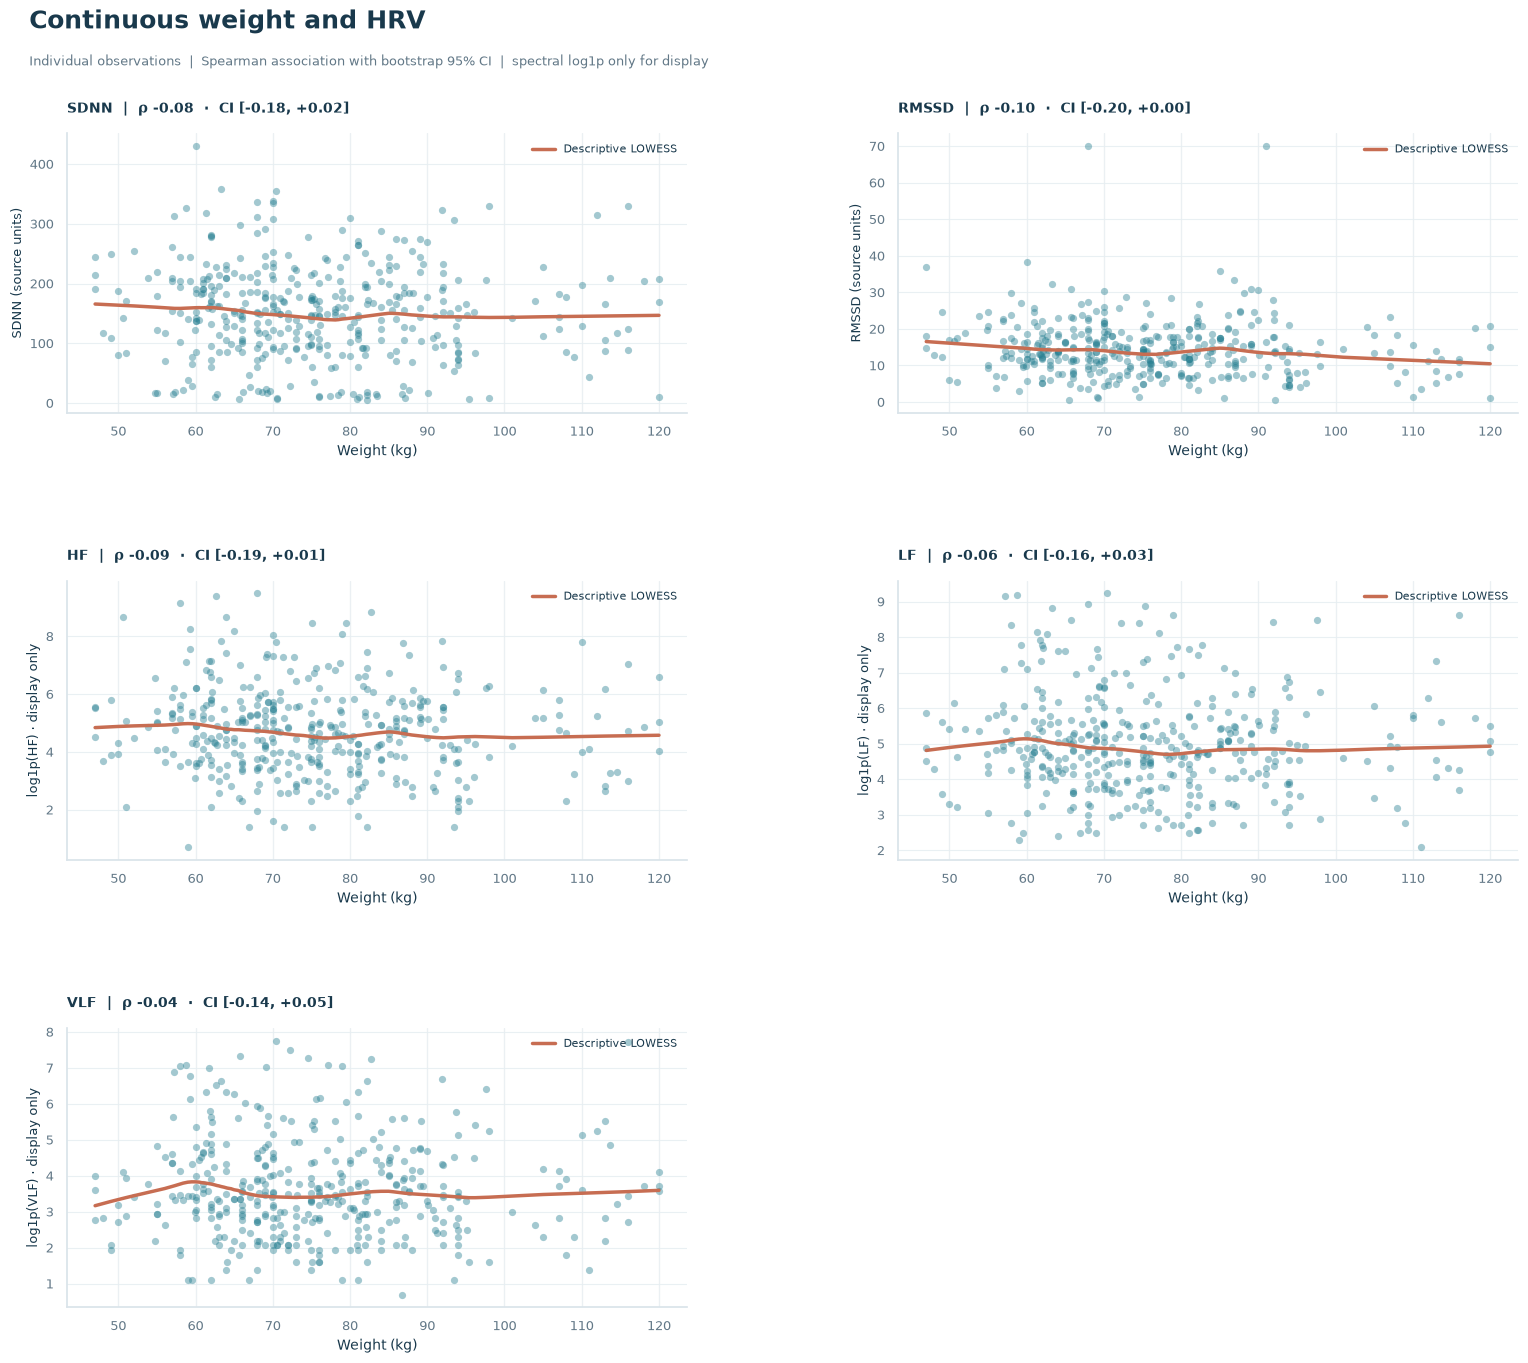

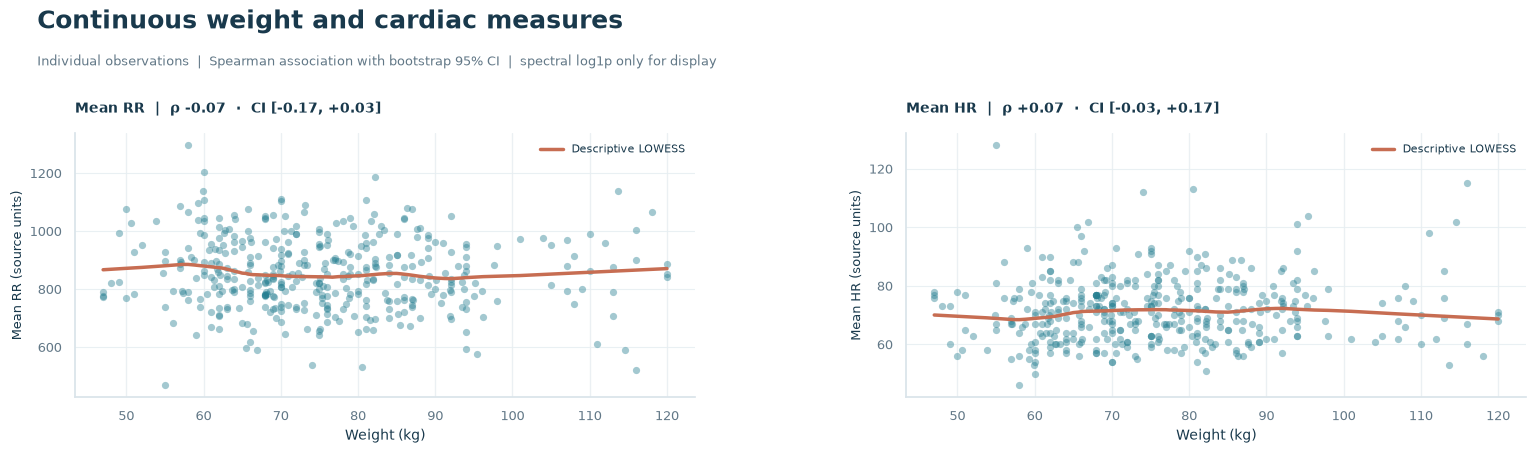

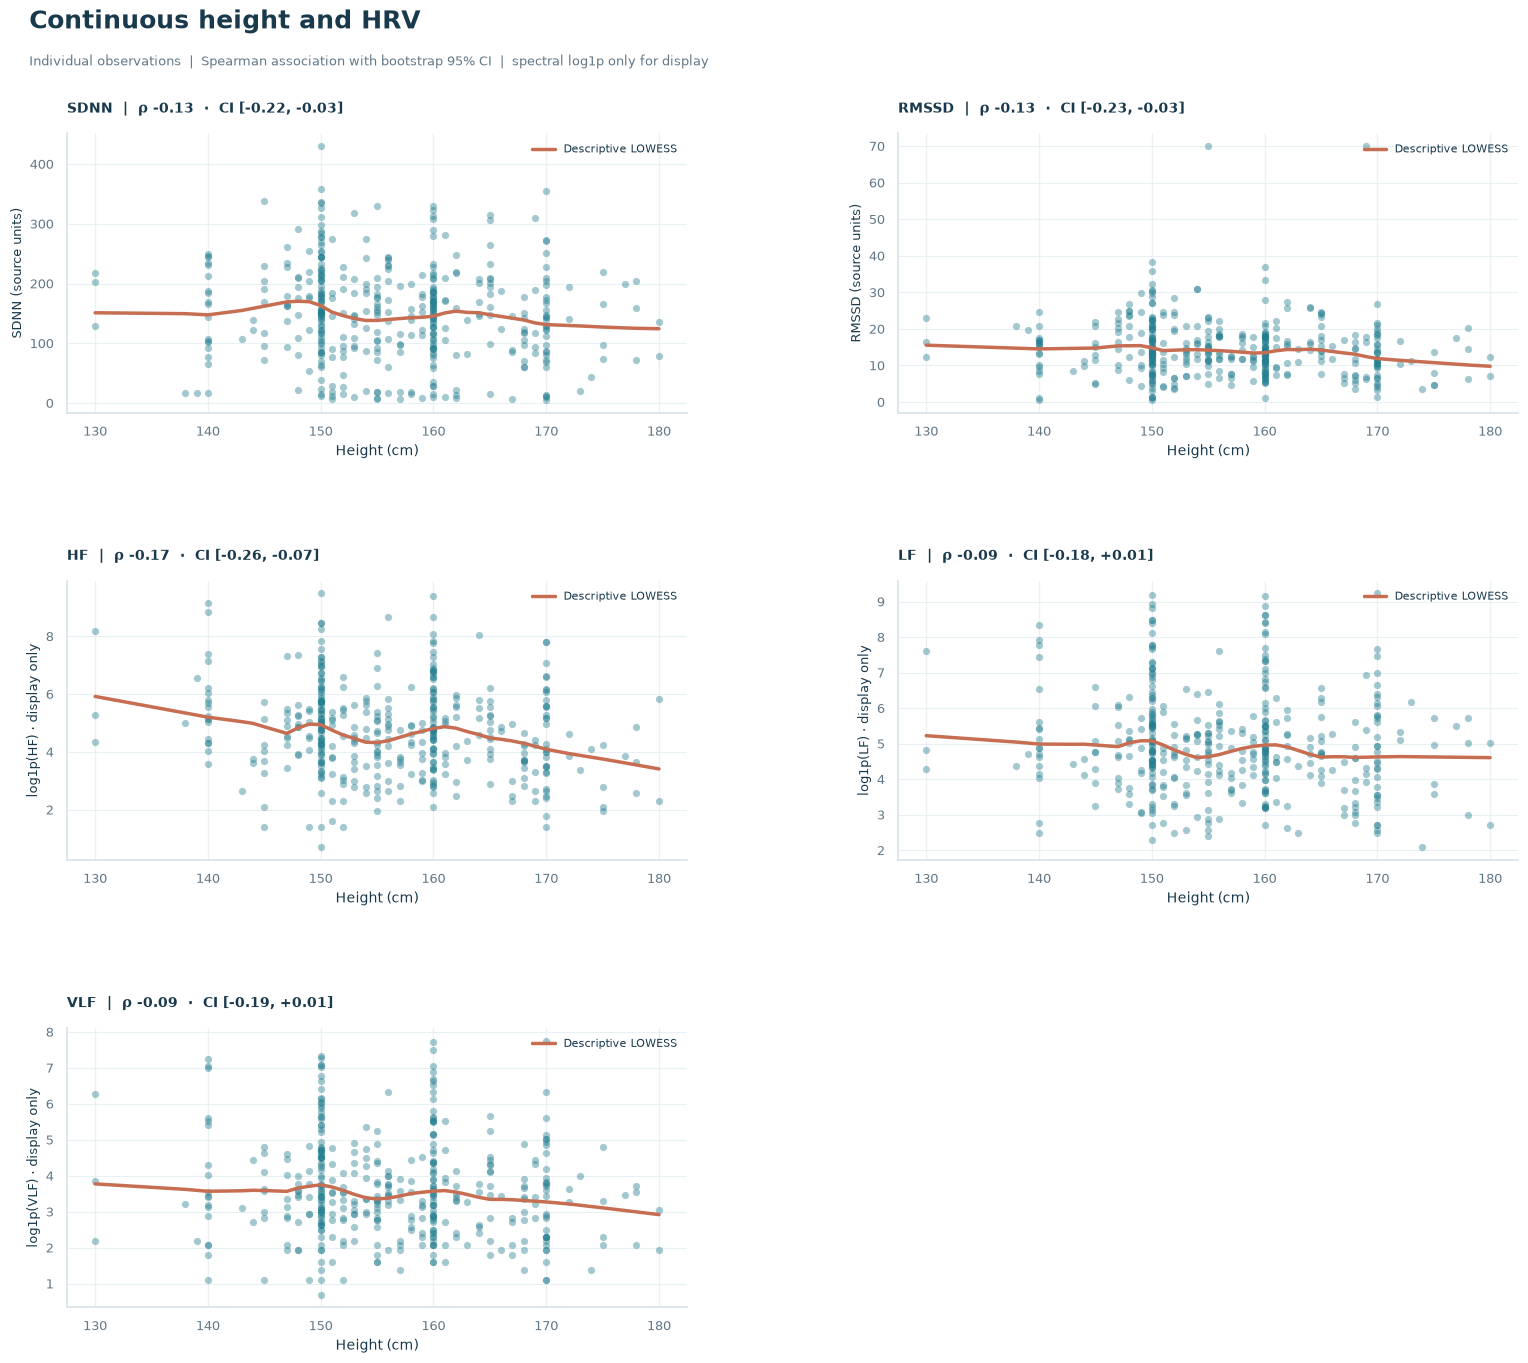

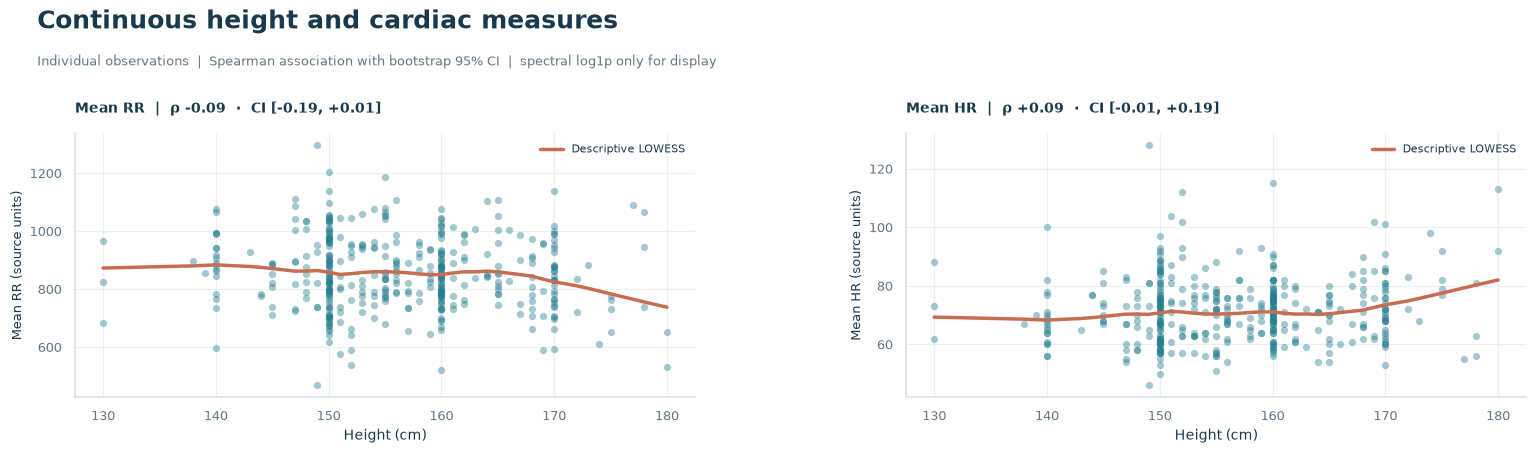

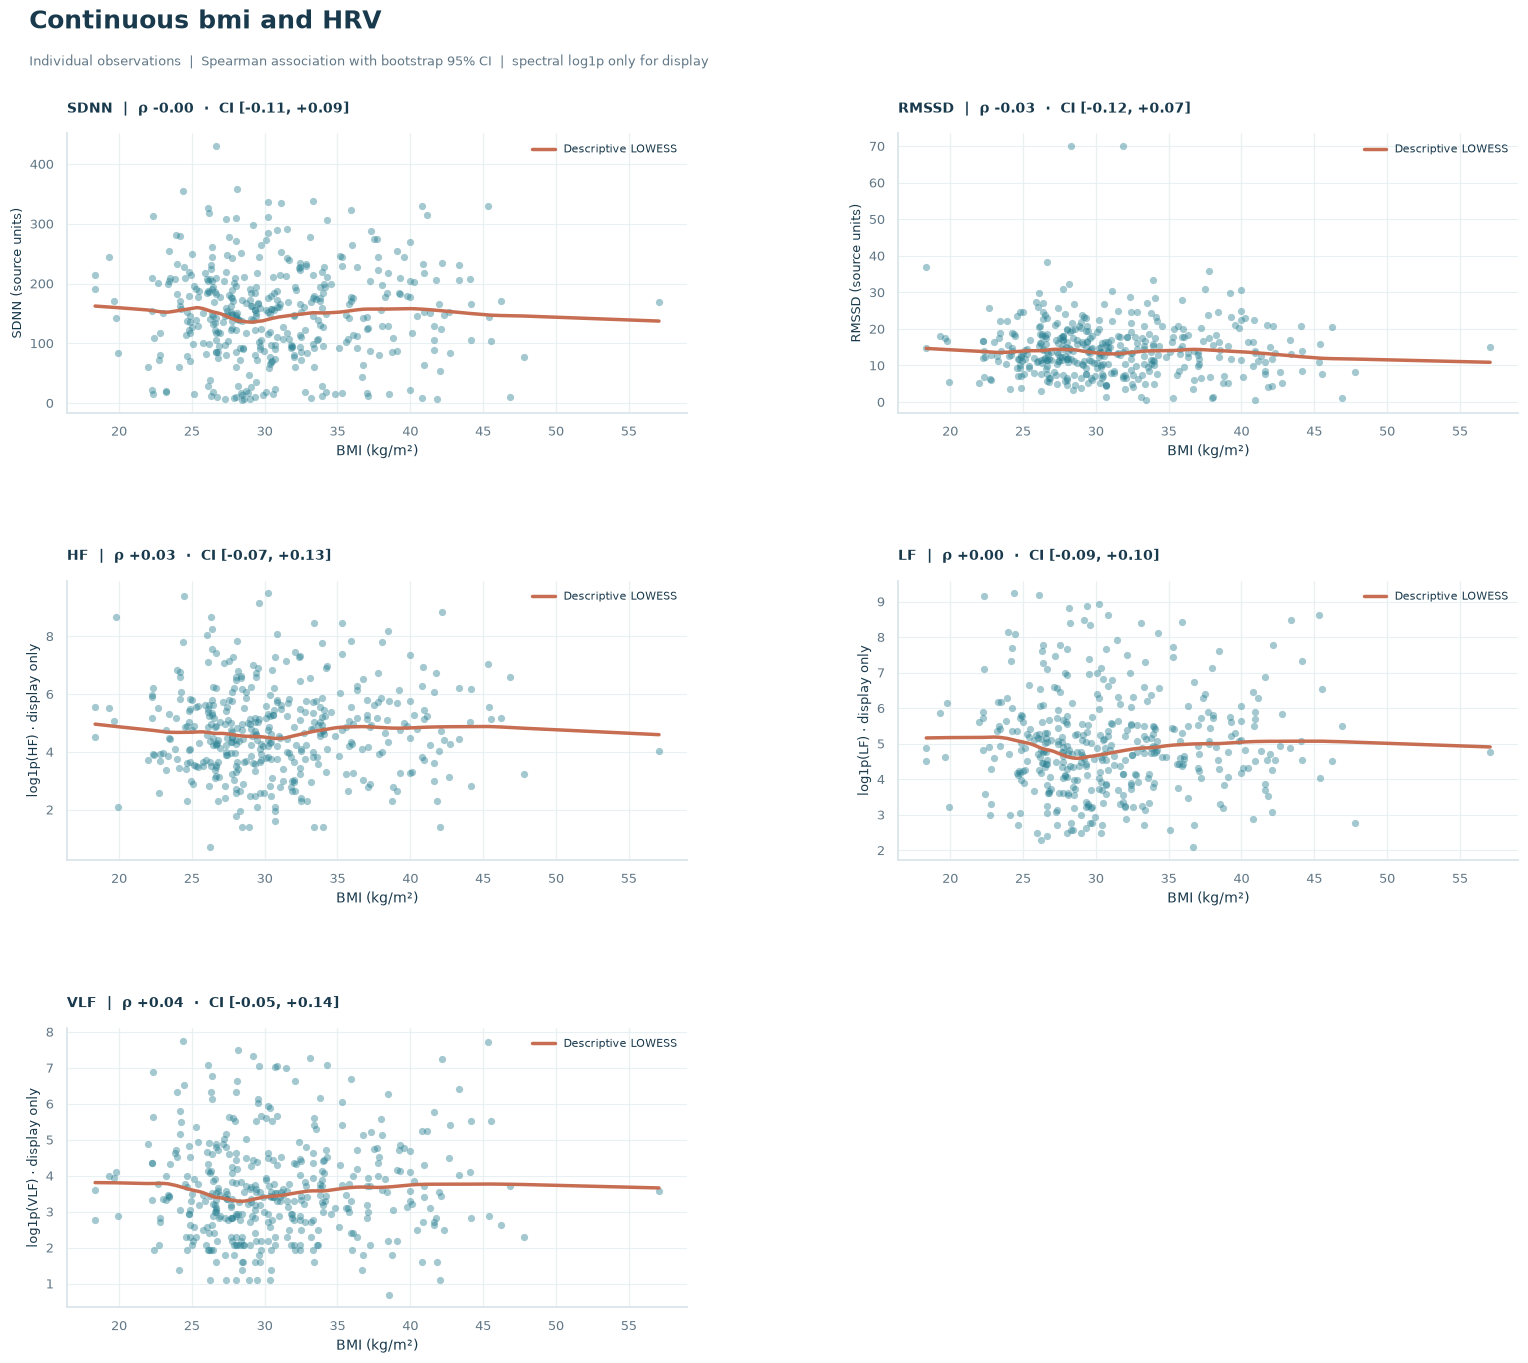

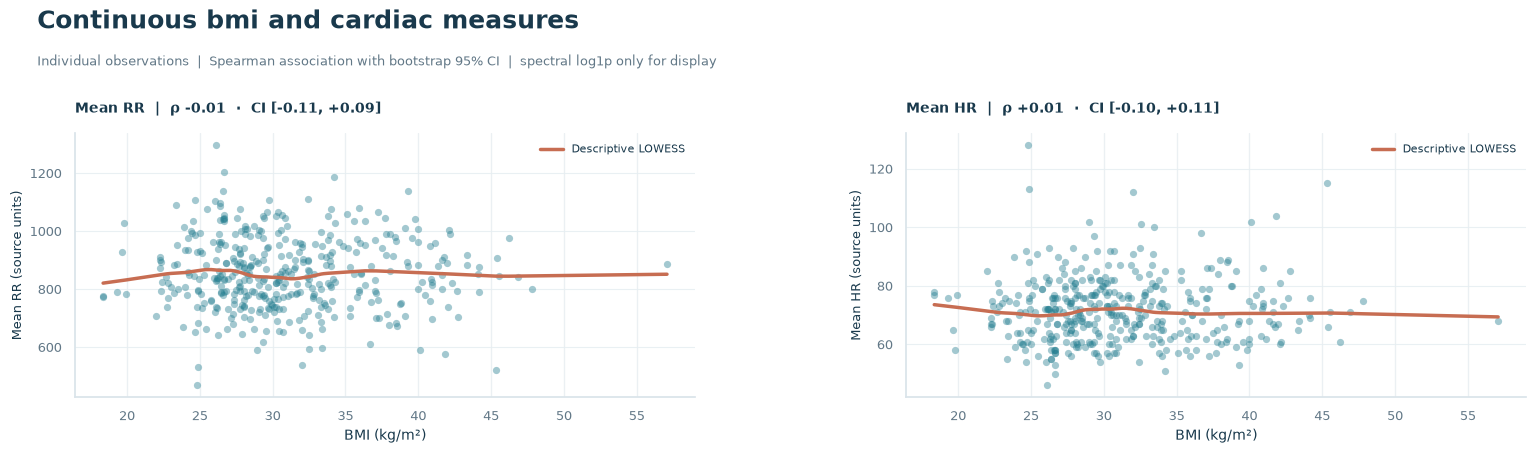

In [10]:
def scatter_sheet(factor, subset, filename):
    factor_label, factor_axis = CONTINUOUS[factor]
    selected = list(PRIMARY if subset == "primary" else COMPLEMENTARY)
    rows = int(np.ceil(len(selected)/2))
    fig, axes = plt.subplots(rows, 2, figsize=(16.4, 4.55*rows + .25), squeeze=False)
    axes = axes.reshape(-1)
    x = data[factor].to_numpy(dtype=float)
    indexed = continuous.loc[continuous.factor == factor].set_index("outcome")
    for ax, outcome in zip(axes, selected):
        y, ylabel = values_for_plot(outcome)
        sns.scatterplot(x=x, y=y, color=TEAL, s=27, alpha=.42, linewidth=0, ax=ax)
        if LOWESS_AVAILABLE:
            trend = lowess(y, x, frac=.40, it=1, return_sorted=True)
            ax.plot(trend[:, 0], trend[:, 1], color=CORAL, lw=2.5,
                    label="Descriptive LOWESS")
        result = indexed.loc[outcome]
        ax.set_title(f"{MEASURES[outcome]}  |  ρ {result.spearman_rho:+.2f}"
                     f"  ·  CI [{result.rho_ci_low:+.2f}, {result.rho_ci_high:+.2f}]",
                     fontsize=10.2, color=NAVY, loc="left", pad=15)
        ax.set_xlabel(factor_axis, fontsize=10)
        ax.set_ylabel(ylabel, fontsize=9.5)
        if LOWESS_AVAILABLE:
            ax.legend(frameon=False, loc="upper right", fontsize=8)
        style_axis(ax)
    for ax in axes[len(selected):]:
        ax.axis("off")
    figure_header(fig, f"Continuous {factor_label.lower()} and {'HRV' if subset == 'primary' else 'cardiac measures'}",
                  "Individual observations  |  Spearman association with bootstrap 95% CI  |  spectral log1p only for display")
    plot_area(fig, left=.085, bottom_inches=.78, top_inches=1.38, hspace=.60)
    save_figure(fig, filename, f"Continuous {factor_label}: {subset} measures, scatterplots and optional LOWESS")


for factor, (label, _) in CONTINUOUS.items():
    number = {"weight_kg": "01", "height_cm": "03", "imc": "05"}[factor]
    next_number = {"weight_kg": "02", "height_cm": "04", "imc": "06"}[factor]
    tag = {"weight_kg": "weight", "height_cm": "height", "imc": "bmi"}[factor]
    scatter_sheet(factor, "primary", f"{number}_{tag}_primary_hrv_scatter.png")
    scatter_sheet(factor, "complementary", f"{next_number}_{tag}_complementary_scatter.png")

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


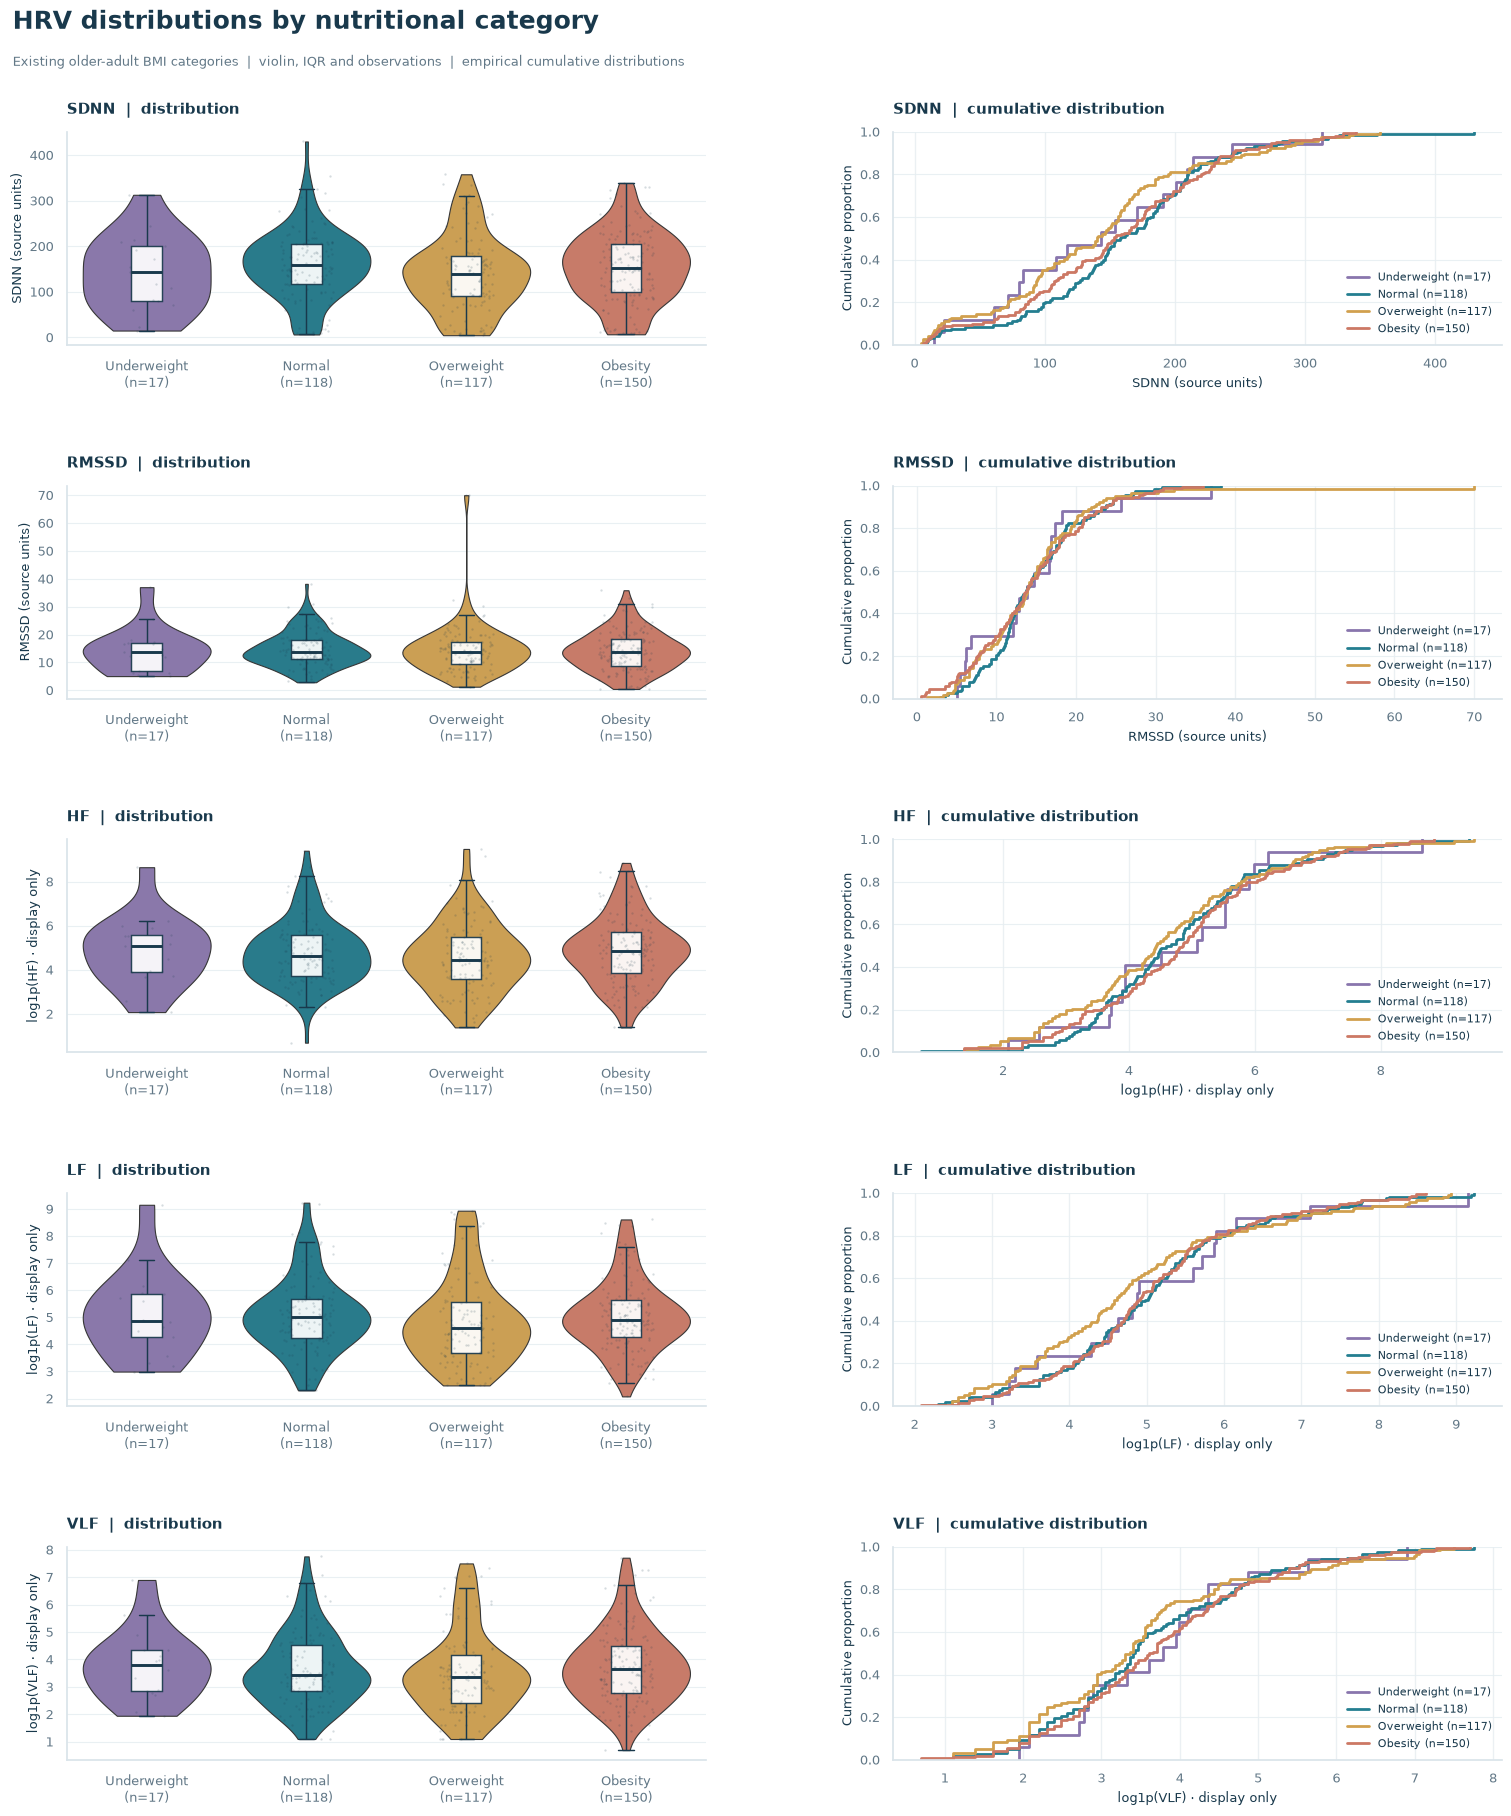

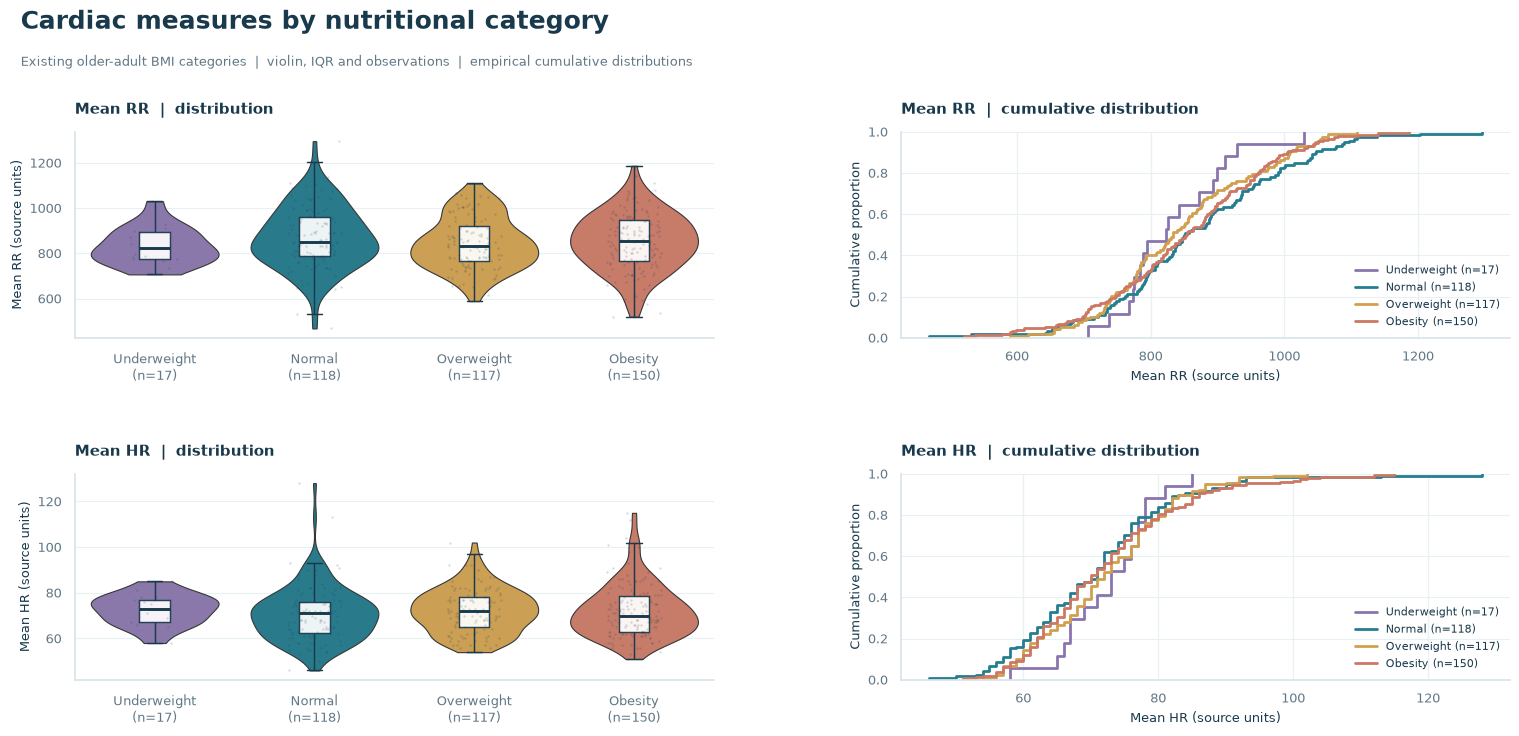

In [11]:
def bmi_distribution_sheet(subset, filename):
    selected = list(PRIMARY if subset == "primary" else COMPLEMENTARY)
    rows = len(selected)
    fig, axes = plt.subplots(rows, 2, figsize=(16.4, 3.60*rows + .5), squeeze=False,
                             gridspec_kw={"width_ratios": [1.05, 1]})
    group_sizes = data.bmi_category.value_counts().reindex(BMI_ORDER)
    for i, outcome in enumerate(selected):
        ax_dist, ax_ecdf = axes[i]
        vals, ylabel = values_for_plot(outcome)
        frame = pd.DataFrame({"category": data.bmi_category.to_numpy(), "value": vals})
        sns.violinplot(data=frame, x="category", y="value", order=BMI_ORDER, hue="category",
                       palette=BMI_COLORS, legend=False, density_norm="width", cut=0,
                       inner=None, linewidth=.8, saturation=.91, ax=ax_dist)
        sns.boxplot(data=frame, x="category", y="value", order=BMI_ORDER, width=.19,
                    showfliers=False, color="white", linewidth=1.05,
                    boxprops={"edgecolor": NAVY, "facecolor": "white", "alpha": .92},
                    whiskerprops={"color": NAVY}, medianprops={"color": NAVY, "linewidth": 2.1},
                    capprops={"color": NAVY}, ax=ax_dist)
        sns.stripplot(data=frame, x="category", y="value", order=BMI_ORDER, color=NAVY,
                      size=1.65, alpha=.18, jitter=.17, ax=ax_dist)
        ax_dist.set_xticks(range(len(BMI_ORDER)), [f"{g}\n(n={group_sizes[g]})" for g in BMI_ORDER])
        ax_dist.set_xlabel("")
        ax_dist.set_ylabel(ylabel, fontsize=9.1)
        ax_dist.set_title(f"{MEASURES[outcome]}  |  distribution", loc="left", fontsize=10.8, pad=13)

        for category in BMI_ORDER:
            v = frame.loc[frame.category == category, "value"]
            sns.ecdfplot(x=v, ax=ax_ecdf, linewidth=2.0, color=BMI_COLORS[category],
                         label=f"{category} (n={group_sizes[category]})")
        ax_ecdf.set_title(f"{MEASURES[outcome]}  |  cumulative distribution", loc="left", fontsize=10.8, pad=13)
        ax_ecdf.set_xlabel(ylabel, fontsize=9.1)
        ax_ecdf.set_ylabel("Cumulative proportion", fontsize=9.1)
        ax_ecdf.legend(frameon=False, fontsize=8, loc="lower right")
        for ax in [ax_dist, ax_ecdf]:
            style_axis(ax)

    figure_header(fig, "HRV distributions by nutritional category" if subset == "primary"
                  else "Cardiac measures by nutritional category",
                  "Existing older-adult BMI categories  |  violin, IQR and observations  |  empirical cumulative distributions")
    plot_area(fig, left=.095, bottom_inches=.86, top_inches=1.36, wspace=.30, hspace=.66)
    save_figure(fig, filename, f"BMI category profiles for {subset} outcomes, with ECDF")


bmi_distribution_sheet("primary", "07_bmi_category_primary_hrv_profiles.png")
bmi_distribution_sheet("complementary", "08_bmi_category_complementary_profiles.png")

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


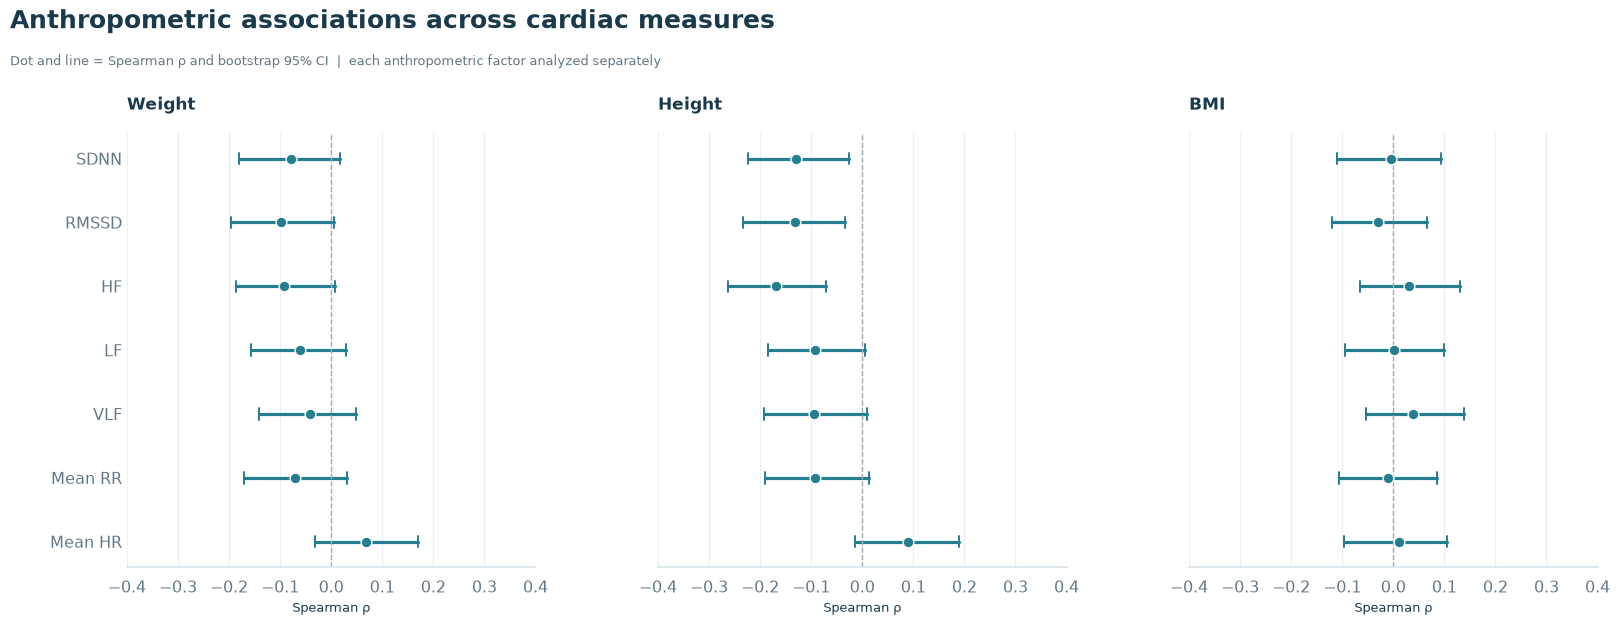

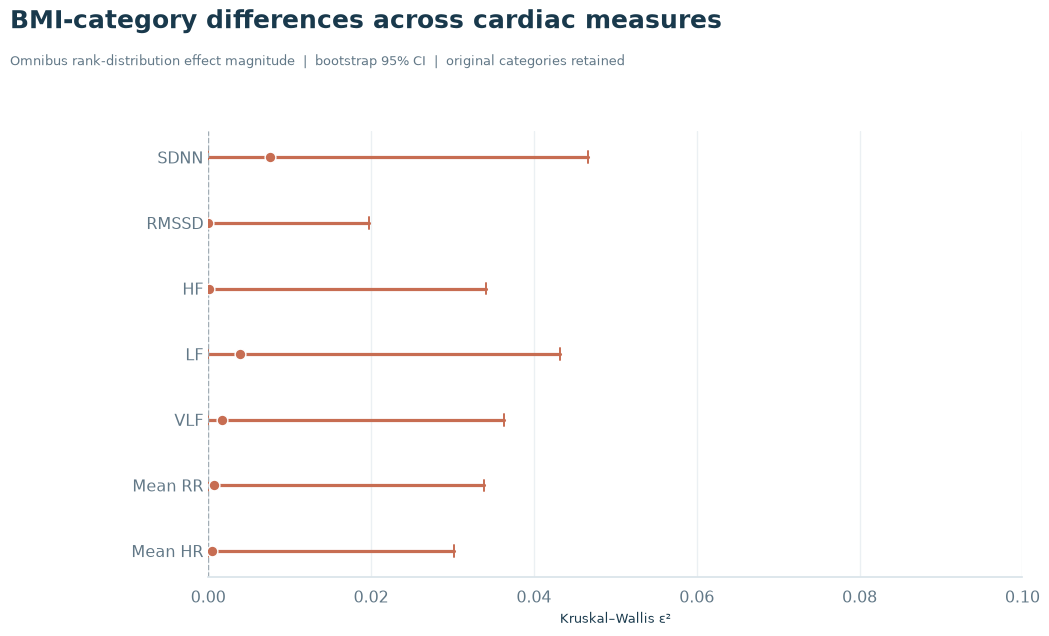

In [12]:
def forest_panel(ax, estimates, low_col, high_col, effect_col, labels, color, xlim, xlabel):
    positions = np.arange(len(estimates))[::-1]
    center = estimates[effect_col].to_numpy(dtype=float)
    low = estimates[low_col].to_numpy(dtype=float)
    high = estimates[high_col].to_numpy(dtype=float)
    for ypos, value, lo, hi in zip(positions, center, low, high):
        ax.plot([lo, hi], [ypos, ypos], lw=2.3, color=color, solid_capstyle="round")
        ax.plot([lo, lo], [ypos-.09, ypos+.09], lw=1.4, color=color)
        ax.plot([hi, hi], [ypos-.09, ypos+.09], lw=1.4, color=color)
        ax.scatter(value, ypos, s=60, color=color, edgecolors="white", zorder=3)
    ax.axvline(0, color="#A2ADB5", lw=1, ls="--")
    ax.set_yticks(positions, labels)
    ax.set_xlim(*xlim)
    ax.set_xlabel(xlabel, fontsize=9.5)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", color="#E6EDF1")
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)


def anthropometric_forest():
    fig, axes = plt.subplots(1, 3, figsize=(17.2, 6.6), sharey=True)
    names = list(MEASURES.values())
    observed_limit = np.nanmax(np.abs(continuous[["rho_ci_low", "rho_ci_high"]].to_numpy(dtype=float)))
    rho_extent = float(min(1, max(.3, np.ceil((observed_limit + .04) * 10) / 10)))
    for ax, (factor, (label, _)) in zip(axes, CONTINUOUS.items()):
        chosen = continuous.loc[continuous.factor == factor].set_index("outcome").loc[list(MEASURES)].reset_index()
        forest_panel(ax, chosen, "rho_ci_low", "rho_ci_high", "spearman_rho",
                     names, TEAL, (-rho_extent, rho_extent), "Spearman ρ")
        ax.set_title(label, fontsize=12, color=NAVY, loc="left", pad=17)
    figure_header(fig, "Anthropometric associations across cardiac measures",
                  "Dot and line = Spearman ρ and bootstrap 95% CI  |  each anthropometric factor analyzed separately")
    plot_area(fig, left=.13, right=.985, bottom_inches=.88, top_inches=1.38, wspace=.30)
    save_figure(fig, "09_anthropometric_spearman_forest.png",
                "Forest comparisons of weight, height and BMI Spearman estimates")


def bmi_effect_forest():
    fig, ax = plt.subplots(figsize=(11.8, 6.7))
    chosen = bmi_omnibus.set_index("outcome").loc[list(MEASURES)].reset_index()
    observed_limit = np.nanmax(bmi_omnibus["epsilon_ci_high"].to_numpy(dtype=float))
    epsilon_upper = float(min(1, max(.10, np.ceil((observed_limit + .02) * 20) / 20)))
    forest_panel(ax, chosen, "epsilon_ci_low", "epsilon_ci_high", "epsilon_squared",
                 list(MEASURES.values()), CORAL, (0, epsilon_upper), "Kruskal–Wallis ε²")
    figure_header(fig, "BMI-category differences across cardiac measures",
                  "Omnibus rank-distribution effect magnitude  |  bootstrap 95% CI  |  original categories retained")
    plot_area(fig, left=.23, right=.92, bottom_inches=.88, top_inches=1.36)
    save_figure(fig, "10_bmi_category_epsilon_forest.png", "Kruskal–Wallis epsilon-squared estimates by outcome")


anthropometric_forest()
bmi_effect_forest()

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


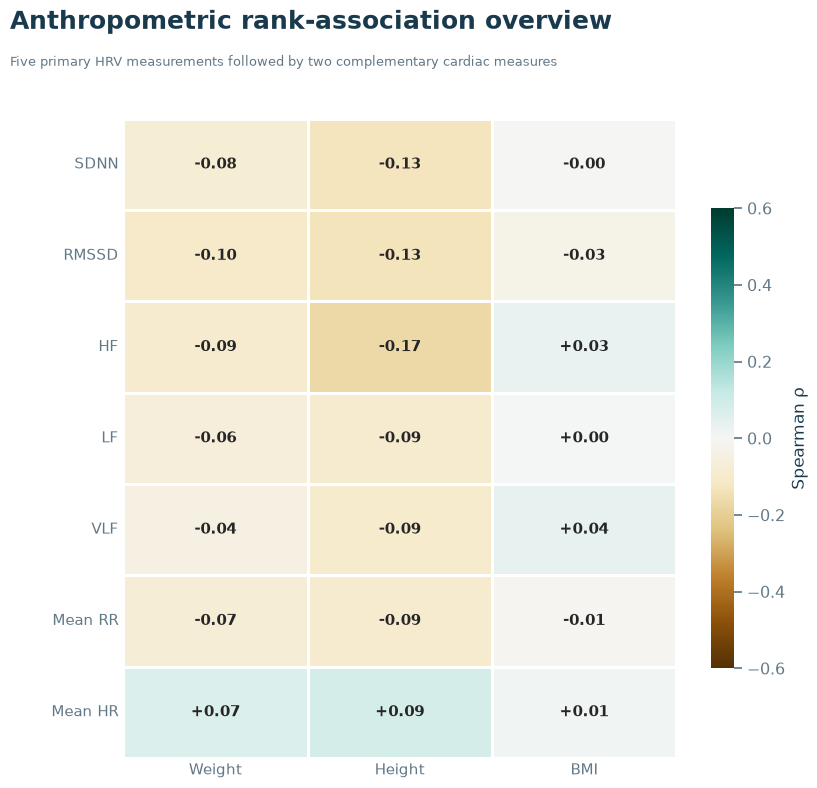

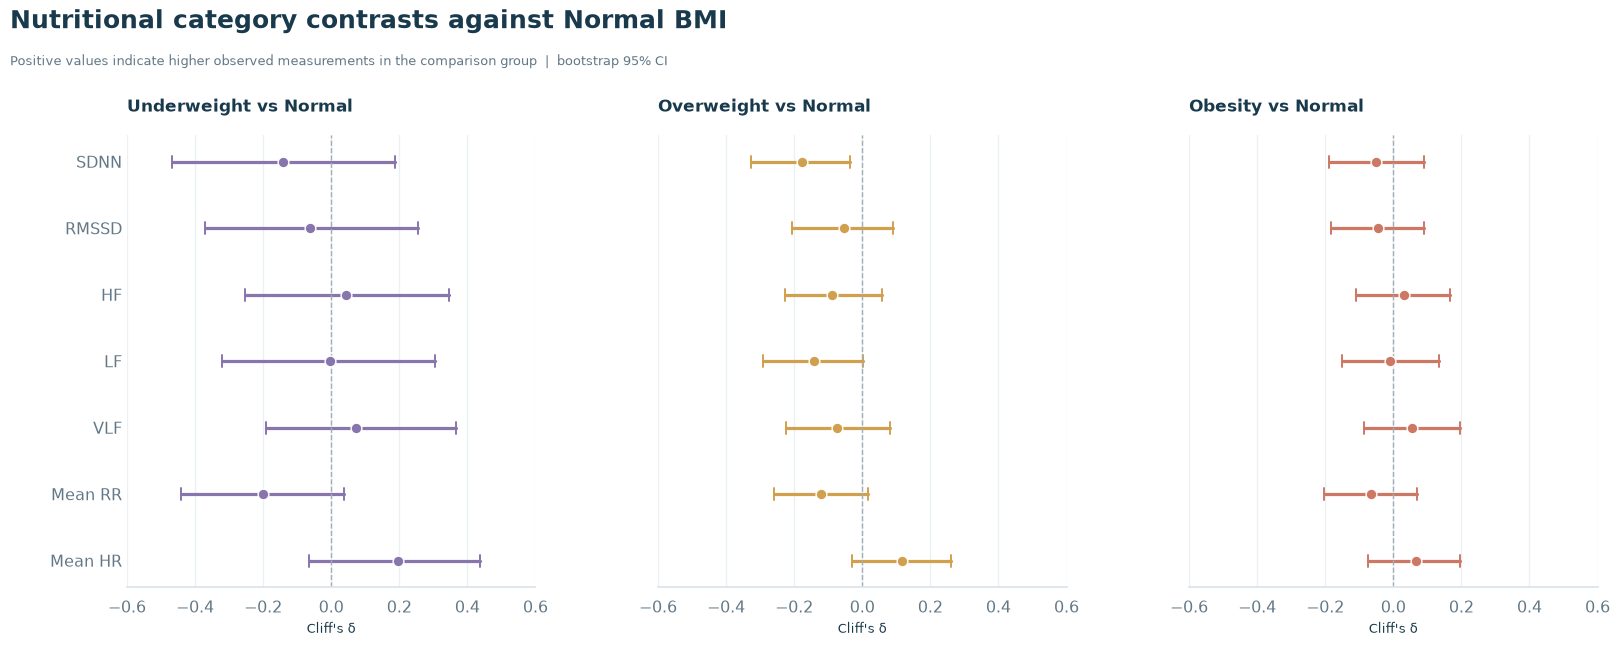

In [13]:
def association_heatmap():
    matrix = continuous.pivot(index="outcome_label", columns="factor_label", values="spearman_rho")
    matrix = matrix.reindex(index=list(MEASURES.values()), columns=[value[0] for value in CONTINUOUS.values()])
    fig, ax = plt.subplots(figsize=(9.6, 8.3))
    sns.heatmap(matrix, annot=True, fmt="+.2f", cmap="BrBG", center=0, vmin=-.6, vmax=.6,
                linewidths=1.8, linecolor="white", square=False,
                cbar_kws={"label": "Spearman ρ", "shrink": .72},
                annot_kws={"size": 11, "weight": "semibold"}, ax=ax)
    ax.set_ylabel("")
    ax.set_xlabel("")
    ax.set_yticklabels(matrix.index, rotation=0, fontsize=11)
    ax.set_xticklabels(matrix.columns, rotation=0, fontsize=11)
    ax.tick_params(axis="both", length=0)
    figure_header(fig, "Anthropometric rank-association overview",
                  "Five primary HRV measurements followed by two complementary cardiac measures")
    plot_area(fig, left=.18, right=.90, bottom_inches=.68, top_inches=1.23)
    save_figure(fig, "11_anthropometric_spearman_heatmap.png",
                "Correlations for three continuous anthropometric factors and seven outcomes")


def bmi_contrast_forest():
    if not RUN_BMI_REFERENCE_CONTRASTS:
        return
    fig, axes = plt.subplots(1, 3, figsize=(17.2, 6.8), sharey=True)
    names = list(MEASURES.values())
    observed_limit = np.nanmax(np.abs(bmi_pairs[["cliffs_ci_low", "cliffs_ci_high"]].to_numpy(dtype=float)))
    delta_extent = float(min(1, max(.3, np.ceil((observed_limit + .04) * 10) / 10)))
    for ax, group in zip(axes, BMI_CONTRASTS):
        chosen = bmi_pairs.loc[bmi_pairs.comparison == group].set_index("outcome").loc[list(MEASURES)].reset_index()
        forest_panel(ax, chosen, "cliffs_ci_low", "cliffs_ci_high",
                     "cliffs_delta_comparison_vs_normal", names, BMI_COLORS[group],
                     (-delta_extent, delta_extent), "Cliff's δ")
        ax.set_title(f"{group} vs Normal", fontsize=12, color=NAVY, loc="left", pad=17)
    figure_header(fig, "Nutritional category contrasts against Normal BMI",
                  "Positive values indicate higher observed measurements in the comparison group  |  bootstrap 95% CI")
    plot_area(fig, left=.13, right=.985, bottom_inches=.88, top_inches=1.40, wspace=.30)
    save_figure(fig, "12_bmi_category_vs_normal_cliffs_forest.png",
                "Exploratory Cliff's delta effect estimates for three Normal-reference contrasts")


association_heatmap()
bmi_contrast_forest()

## 9. Manifest and autogenerated documentation

The README documents methods and decisions, while the results report summarizes **every** main estimate, including non-significant results. Results are generated from the computed tables; no conclusions are pre-written. All files are exported to this notebook's dedicated outputs directory.

In [14]:
save_table(pd.DataFrame(figure_manifest), "figure_manifest.csv")
run_info = pd.DataFrame([{
    "input_file": str(input_file), "n_records": len(data),
    "outcomes": " | ".join(MEASURES), "continuous_factors": " | ".join(CONTINUOUS),
    "categorical_factor": "bmi_category", "bmi_levels": " | ".join(BMI_ORDER),
    "bootstrap_replicates": N_BOOT, "seed": SEED, "confidence_level": CONFIDENCE_LEVEL,
    "python": platform.python_version(), "pandas": pd.__version__,
    "numpy": np.__version__, "scipy": __import__("scipy").__version__,
    "seaborn": sns.__version__, "matplotlib": matplotlib.__version__,
    "lowess_available": LOWESS_AVAILABLE,
}])
save_table(run_info, "run_information.csv")

readme = f"""# 06.02 Anthropometric associations with HRV

## Scope

Single-factor analysis of source measurements `weight_kg`, `height_cm`, `imc`, and existing `bmi_category` against seven cardiac outcomes. No interaction, adjusted regression, categorical recoding, missingness-based exclusion, or source modification.

## Data

- Source: `{input_file}`
- Actual records analyzed: {len(data)}
- Category levels: {', '.join(BMI_ORDER)}
- Source categories are already based on the older-adult MINSAL definition established during preprocessing. No BMI cutoffs are recomputed here.
- Five main HRV measures: {', '.join(PRIMARY.values())}
- Complementary cardiac measures: {', '.join(COMPLEMENTARY.values())}

## Estimation

1. Complete within-category profiles: n, mean, SD, median, P05, P25, P75, P95 and IQR. Overall cohort summary is included.
2. Continuous weight, height and BMI: Spearman rho, two-sided p, paired-percentile-bootstrap 95% CI; exact observed n reported.
3. BMI categories: Kruskal–Wallis H, epsilon-squared (finite-sample negative values truncated to zero), within-group percentile-bootstrap 95% CI.
4. Exploratory contrasts against the Normal BMI reference: Underweight, Overweight and Obesity separately, using two-sided Mann–Whitney U, Cliff's delta, sample median difference and stratified-bootstrap 95% CIs; Holm correction within outcome across the three contrasts.
5. Domain-specific BH-FDR across 20 primary-HRV tests (5 outcomes × 4 factors) and separately across 8 complementary cardiac tests (2 outcomes × 4 factors). Category-pair p-values are separately Holm-adjusted. Domain-level adjustments do not imply study-wide adjustment.
6. Optional LOWESS curves visualize observed trends only; they are not fitted inferential models. HF/LF/VLF may be plotted in a labeled log1p scale; inference and tables use raw data.



## Multiple-testing scope

Benjamini–Hochberg FDR is applied **within the anthropometric domain only**: 20 primary-HRV tests (five HRV measurements × three continuous factors and one BMI-category omnibus comparison) and eight complementary cardiac tests form separate families. The three exploratory BMI-category comparisons against Normal are Holm-corrected within each outcome. These q-values are **not adjusted jointly** with demographic and blood-pressure analyses; notebooks 06.01–06.03 together contain 65 primary-HRV tests and 26 complementary tests. The synthesis retains the source q-values unchanged, without any study-wide FDR claim.

## Generated output tables

- `tables/bmi_category_hrv_descriptive_profiles.csv`
- `tables/anthropometric_continuous_spearman.csv`
- `tables/bmi_category_kruskal_wallis.csv`
- `tables/bmi_category_vs_normal_exploratory.csv` (when enabled)
- `tables/anthropometric_multiplicity_fdr_bh.csv`
- `tables/figure_manifest.csv`
- `tables/run_information.csv`

## Figures

`figures/multipanels/` has {len(figure_manifest)} publication-oriented multipanel plots. Figure names and descriptions are listed in `tables/figure_manifest.csv`. Design deliberately reserves header space to separate figure headings, annotations and panel content.

## Interpretation boundaries

The associations are marginal, observational and unadjusted. BMI is computed from weight and height, so these factors cannot be treated as independent biological evidence. A significant rank-based Mann–Whitney or Kruskal–Wallis test is not automatically a test of equal group medians. A non-significant association is not evidence of equivalence or zero effect. Sparse BMI categories are retained, and uncertainty must be interpreted accordingly. Sampling between source projects and possible non-independence are not resolved by these analyses.

## Environment

Python {platform.python_version()}, pandas {pd.__version__}, NumPy {np.__version__}, SciPy {__import__('scipy').__version__}, Seaborn {sns.__version__}, Matplotlib {matplotlib.__version__}. Bootstrap replicates: {N_BOOT}. Random seed: {SEED}.
"""
(output_root / "README_06_02_anthropometric_associations.md").write_text(readme, encoding="utf-8")

report = "# 06.02 Anthropometric associations with HRV — Results\n\n"
report += f"**Input:** `{input_file.name}`  |  **Records:** {len(data)}  |  **Outcomes:** 7\n\n"
report += "## Nutritional group sample sizes\n\n"
counts = data.bmi_category.value_counts().reindex(BMI_ORDER)
for name, count in counts.items():
    report += f"- {name}: {count} ({count/len(data)*100:.1f}%)\n"
report += "\n## Spearman associations with continuous anthropometry\n\n"
report += md_table(continuous, ["factor_label", "outcome_label", "n", "spearman_rho",
                                "rho_ci_low", "rho_ci_high", "p_raw", "p_fdr_bh"])
report += "\n\n## BMI-category omnibus comparisons\n\n"
report += md_table(bmi_omnibus, ["outcome_label", "kruskal_h", "epsilon_squared",
                                  "epsilon_ci_low", "epsilon_ci_high", "p_raw", "p_fdr_bh"])
if RUN_BMI_REFERENCE_CONTRASTS:
    report += "\n\n## Exploratory contrasts compared with Normal BMI\n\n"
    report += md_table(bmi_pairs, ["outcome_label", "comparison", "n_comparison", "n_reference",
                                   "median_difference_comparison_minus_normal", "median_diff_ci_low",
                                   "median_diff_ci_high", "cliffs_delta_comparison_vs_normal",
                                   "cliffs_ci_low", "cliffs_ci_high", "p_raw", "p_holm_within_outcome"])
report += "\n\n## Interpretation boundaries\n\n"
report += ("Associations are unadjusted and observational. Estimates for weight, height and BMI are not "
           "independent biological evidence because BMI is derived from weight and height. "
           "Bootstrap intervals reflect independent-record resampling and do not account for project-level structure. "
           "No result is filtered based on significance. Complete within-category percentiles, means and dispersion "
           "are provided in the CSV descriptive table. Results should not be given causal interpretations.\n")
(output_root / "06_02_anthropometric_associations_results.md").write_text(report, encoding="utf-8")

print("Saved figures:", len(figure_manifest))
print("Saved tables:", len(list(tables_dir.glob("*.csv"))))
print("Results and methods:", output_root)
print("All source data retained; outputs are separate from dataset_final.csv.")

Saved figures: 12
Saved tables: 7
Results and methods: /home/david/Desktop/colabs/nunez_cristian_colabs/heart_variability_rate_profiles/eda_results/hrv_associations/06_02_anthropometric_associations
All source data retained; outputs are separate from dataset_final.csv.
